# MTM field widths: GS2 $\phi$ and $A_\parallel$ equivalent Gaussian widths in $\theta_b$, width laws, predicted GFTM settings

Fusion_PhD-bhx7.17. The user (2026-11-17): use the extent-to-width transformation to get the width of each GS2 MTM's $\phi$ and
$A_\parallel$ separately, look at their distributions, fit width laws, and ask whether one set of GFTM settings can resolve both.

**The conversion is analytic, in the basis coordinate.** TGLF and GFTM expand each field in $\psi_n(x)\propto H_n(x)e^{-x^2/2}$ with
$x=\theta_b/\mathrm{WIDTH}$, where $\theta_b=2\pi l_\parallel/L_{\rm turn}$ is the arc length along the field line, not $\theta$.
pyrokinetics now maps $\theta\to\theta_b$ exactly from each sample's geometry: `FieldLine.compute_basis_angle` (pyro PR #617, the
cumulative form of `compute_length_per_turn`). In $\theta_b$, the 95 % extent of $|f|^2$ (pyro `Extent`) is
- $E=2.772\,W$ for an even field, $|\psi_0|^2\propto e^{-x^2}$;
- $E=3.953\,W$ for an odd field, $|\psi_1|^2\propto x^2e^{-x^2}$.

An MTM has tearing parity: $A_\parallel$ even, $\phi$ odd. So $W_{A_\parallel}=E^{\theta_b}_{A_\parallel}/2.772$ and $W_\phi=E^{\theta_b}_\phi/3.953$.
No runs are calibrated against. The notebook checks the map against GFTM itself (NBASIS-2 eigenfunctions are pure Hermite functions
in $\theta_b$) and against qp5.49's run-calibrated KBM widths.

**Populations.** GS2 `pyro_cube_avg` of NSTX_MTM n1000 (fit) and n300 (out of sample), as the law2 refit (`mtm_extent_law_refit`):
label MTM ($T>0.15$, $\omega<0$), $\gamma>0$, `growth_rate_tolerance` $<0.01$. A field whose $|f|^2$ has more than 1 % beyond
$0.9\max|\theta|$ touches the box: its extent, and so its width, is a lower bound (right-censored).

In [1]:
import os
from multiprocessing import get_context
from pathlib import Path
import time
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator, StrMethodFormatter
from scipy import optimize, stats
from scipy.stats import chi2, norm
from pyrokinetics import Pyro, PyroHypercube
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.diagnostics.field_line import FieldLine
from general_analysis import mode_classification as mc

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
plt.rcParams["lines.marker"] = ""     # the style marks every line; reference lines (axvline/axhline) must not carry dots
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
data_root = Path(os.path.expandvars(os.environ["GK_DATA_ROOT"]))     # the WORK tree
plots_dir = ROOT / "Plots" / "mtm_field_widths"
plots_dir.mkdir(parents=True, exist_ok=True)
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))

draws = {"n1000": "beta_q_shat_ky_n1000", "n300": "beta_q_shat_ky_n300"}
arms = {"m11_new": "m11_new", "law2 rule": "extent_rule_tf035_law2", "law2 maxbasis": "extent_maxbasis_law2_s100", "fw174": "gftm_fw174"}
m11_width = 5.89285              # registry gftm_m11_new: FIND_WIDTH F, WIDTH 5.89285 (its cube does not record the width)
fields = ["phi", "apar"]
field_label = {"phi": r"$\phi$", "apar": r"$A_\parallel$"}
mtm_parity = {"phi": "odd", "apar": "even"}
kbm_parity = {"phi": "even", "apar": "odd"}
tolerance_gate, edge_gate = 1e-2, 1e-2
target_error = 0.03              # qp5.49: the extent-convergence criterion behaves like a Gaussian at 3 % relative L2 error
nbasis_cap, nxgrid_cap, nxgrid_floor = 59, 65, 14
kbm_cases = ["SPR-045", "M1", "R4", "R3"]
check_widths = [0.2, 0.4, 0.8, 1.6]
calibration_widths = [0.2, 0.2297, 0.2639, 0.3031, 0.3482, 0.4, 0.4595, 0.5279, 0.6063, 0.6965, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5,
                      1.6, 1.9218, 2.3083, 2.7726, 3.3302, 4.0]   # qp5.49's fixed-width GFTM NBASIS-2 ladder


def extent_95(power, coordinate):
    # pyro's 95 % Extent of |f|^2 over `coordinate` (theta or theta_b), finite points only
    keep = np.isfinite(power)
    return float(Extent._compute(xr.DataArray(power[keep][None], dims=("sample", "theta"), coords=dict(theta=coordinate[keep])), 0.95)[0][0])


def edge_fraction(power, theta):
    # share of |f|^2 beyond 0.9 of the run's own theta box (law2 refit's box-contact measure)
    keep = np.isfinite(power)
    power, theta = power[keep], theta[keep]
    return float(np.trapezoid(power * (abs(theta) > 0.9 * abs(theta).max()), theta) / np.trapezoid(power, theta))

## The analytic factors, and pyro's `Extent` on the models
qp5.43 (`basis_resolution_rule`) quoted $4.32\sigma$ for the odd model, measured with the `Extent` of that time. pyro's `Extent` is
now the central-95 % rule (2.5 % in each tail). On a fine grid it gives the $\chi^2_3$ quantile, $3.953$, for $x\,e^{-x^2/2}$; 4.32 is
not reproduced and is superseded.

In [2]:
analytic_factor = {"even": 2 * norm.ppf(0.975) / np.sqrt(2), "odd": 2 * np.sqrt(chi2.ppf(0.95, 3) / 2)}
x_fine = np.linspace(-12, 12, 200001)
model = {"even": lambda x: np.exp(-x ** 2 / 2), "odd": lambda x: x * np.exp(-x ** 2 / 2)}
for parity in model:
    measured = extent_95(model[parity](x_fine) ** 2, x_fine)
    assert abs(measured - analytic_factor[parity]) < 1e-3, (parity, measured)
    print(f"{parity}: pyro Extent {measured:.4f}, analytic {analytic_factor[parity]:.4f}")
assert abs(extent_95(model["odd"](x_fine) ** 2, x_fine) - 4.32) > 0.3

even: pyro Extent 2.7718, analytic 2.7718
odd: pyro Extent 3.9534, analytic 3.9534


## GS2 MTMs: label, map to $\theta_b$, extent and width per field
Per sample, one `FieldLine` on the sample's own Pyro (its geometry, the cube's $A_\parallel$ attached) gives the tearing parameter $T$
and the map $\theta\to\theta_b$. The label is GA's `classify_T_omega`. Each field's extent is pyro's 95 % `Extent` of $|f|^2$ in
$\theta_b$ (and in $\theta$, for reference); $\phi$ and $A_\parallel$ even fractions (pyro `compute_linear_parity`) check the parity
assumption.

In [5]:
def load_gs2(draw):
    cube_dir = data_root / "GS2/Runs/LATIN_HYPERCUBE/NSTX_MTM" / draws[draw] / "pyro_cube_avg"
    scan = PyroHypercube(pyro=Pyro(gk_file=cube_dir / "pyroscan_base.input", gk_code="GS2"), pyroscan_json=cube_dir / "pyroscan.json",
                         base_directory=cube_dir.parent, file_name="gs2.in")
    scan.load_gk_output(netcdf_file=cube_dir / "cube.nc")
    return scan


projection_widths = np.geomspace(0.5, 32, 19)
n_project = 160


def hermite_functions(x, n=n_project):
    # orthonormal psi_n(x) = H_n(x) exp(-x^2/2) / sqrt(2^n n! sqrt(pi)), n = 0 .. n-1, by the stable recurrence (tglf_hermite.f90's)
    psi = np.zeros((n, len(x)))
    psi[0] = np.pi ** -0.25 * np.exp(-x ** 2 / 2)
    psi[1] = np.sqrt(2) * x * psi[0]
    for k in range(2, n):
        psi[k] = np.sqrt(2 / k) * x * psi[k - 1] - np.sqrt((k - 1) / k) * psi[k - 2]
    return psi


x_check = np.linspace(-40, 40, 40001)
gram = hermite_functions(x_check) @ hermite_functions(x_check).T * (x_check[1] - x_check[0])
assert np.allclose(gram, np.eye(n_project), atol=1e-8)                              # orthonormal to n = 159


def gs2_sample(args):
    draw, i = args
    scan = gs2_scans[draw]
    output = scan.gk_output.data.isel(sample=i)
    finite_theta = output.apar.pint.dequantify().dropna("theta").sortby("theta").theta     # GS2 grids are NaN-padded to the union
    fields_theta = {field: output[field].pint.dequantify().sel(theta=finite_theta) for field in fields}
    field_line = FieldLine(scan.sample_pyro(i, gk_output=xr.Dataset(fields_theta)))
    theta = fields_theta["apar"].theta.values
    basis_angle = field_line.compute_basis_angle(theta)
    row = dict(draw=draw, sample=str(output.sample_name.values), ky=float(output.ky), shat=float(output.shat), q=float(output.q),
               beta=float(output.beta), gamma=float(output.growth_rate.pint.dequantify()),
               omega=mc.ION_DIRECTION * float(output.mode_frequency.pint.dequantify()),
               tolerance=float(output.growth_rate_tolerance.pint.dequantify()),
               T=float(field_line.compute_linear_tearing_parameter().squeeze()),
               phi_even=float(field_line.compute_linear_parity("phi").squeeze()), apar_even=float(field_line.compute_linear_parity("apar").squeeze()),
               stretch=float(np.gradient(basis_angle, theta)[np.argmin(abs(theta))]))
    for field in fields:
        power = np.abs(fields_theta[field].values) ** 2
        row[f"{field}_extent_theta"] = extent_95(power, theta)
        row[f"{field}_extent"] = extent_95(power, basis_angle)
        row[f"{field}_edge"] = edge_fraction(power, theta)
        row[f"{field}_width"] = row[f"{field}_extent"] / analytic_factor[mtm_parity[field]]
        weight = power * np.gradient(basis_angle)
        row[f"{field}_tail_fraction"] = float(weight[abs(basis_angle) > np.pi].sum() / weight.sum())   # |f|^2 beyond the first poloidal turn
        # projection of the complex field onto the code's basis psi_n(theta_b / WIDTH) / sqrt(WIDTH), as qp5.43: relative L2 error after N functions
        values, step = fields_theta[field].values.ravel(), np.gradient(basis_angle)
        for j, width in enumerate(projection_widths):
            coefficients = (hermite_functions(basis_angle / width) / np.sqrt(width)) @ (values * step)
            error = np.sqrt(np.maximum(1 - np.cumsum(np.abs(coefficients) ** 2) / (np.abs(values) ** 2 * step).sum(), 0))
            row[f"{field}_projected_needed_{j}"] = int(np.argmax(error <= target_error)) + 1 if (error <= target_error).any() else np.inf
            for nbasis in (24, nbasis_cap):
                row[f"{field}_projected_error_{nbasis}_{j}"] = float(error[nbasis - 1])
    return row


gs2_scans = {draw: load_gs2(draw) for draw in draws}
with get_context("fork").Pool(n_cpu) as pool:
    gs2 = pd.DataFrame(pool.map(gs2_sample, [(draw, i) for draw in draws for i in range(gs2_scans[draw].gk_output.data.sizes["sample"])], chunksize=8))
gs2["label"] = mc.classify_T_omega(gs2)
check = gs2[(gs2.draw == "n1000") & (gs2["sample"] == "iteration_33")].iloc[0]
assert round(check.ky, 5) == 0.58085 and round(check.shat, 5) == 1.32921        # Fusion_PhD-jmw0 guard: cube coordinates
mtm = gs2[(gs2.label == "MTM") & (gs2.gamma > 0) & (gs2.tolerance < tolerance_gate)].copy()
for field in fields:
    mtm[f"{field}_censored"] = mtm[f"{field}_edge"] >= edge_gate
mtm["ratio"] = mtm.phi_width / mtm.apar_width                                     # s^2 = W_phi / W_A_par
mtm["ratio_censored"] = mtm.phi_censored | mtm.apar_censored
counts = gs2.groupby("draw").agg(loaded=("sample", "size"), MTM=("label", lambda label: (label == "MTM").sum())).join(
    mtm.groupby("draw").agg(MTM_unstable_converged=("sample", "size"), phi_censored=("phi_censored", "sum"), apar_censored=("apar_censored", "sum"),
                            phi_even_median=("phi_even", "median"), apar_even_median=("apar_even", "median"),
                            phi_odd_share=("phi_even", lambda even: (even < 0.5).mean()), apar_even_share=("apar_even", lambda even: (even > 0.5).mean()),
                            stretch_median=("stretch", "median"), apar_tail_median=("apar_tail_fraction", "median"),
                            phi_tail_median=("phi_tail_fraction", "median")))
print(counts.round(3).to_string())

       loaded  MTM  MTM_unstable_converged  phi_censored  apar_censored  phi_even_median  apar_even_median  phi_odd_share  apar_even_share  stretch_median  apar_tail_median  phi_tail_median
draw                                                                                                                                                                                         
n1000    1000  757                     683            58             35              0.0               1.0            1.0              1.0           1.047             0.112            0.599
n300      300  226                     202            14              9              0.0               1.0            1.0              1.0           1.047             0.130            0.616


### What sets $W_{A_\parallel}$: one peak at $\theta_b=0$, or a train of peaks at $\theta_b=2\pi p$
$W_{A_\parallel}$ clusters at discrete values (the width-law figure below shows them as horizontal bands). The share of $|A_\parallel|^2$
beyond the first poloidal turn ($|\theta_b|>\pi$) separates the two shapes; below, $W_{A_\parallel}$ against that share, and one
eigenfunction from each band (median-$\gamma$ MTM of the band, n1000), $|f|^2$ normalised to its peak, against $\theta_b/\pi$, with the
Gaussian (dashed) that has the same extent.

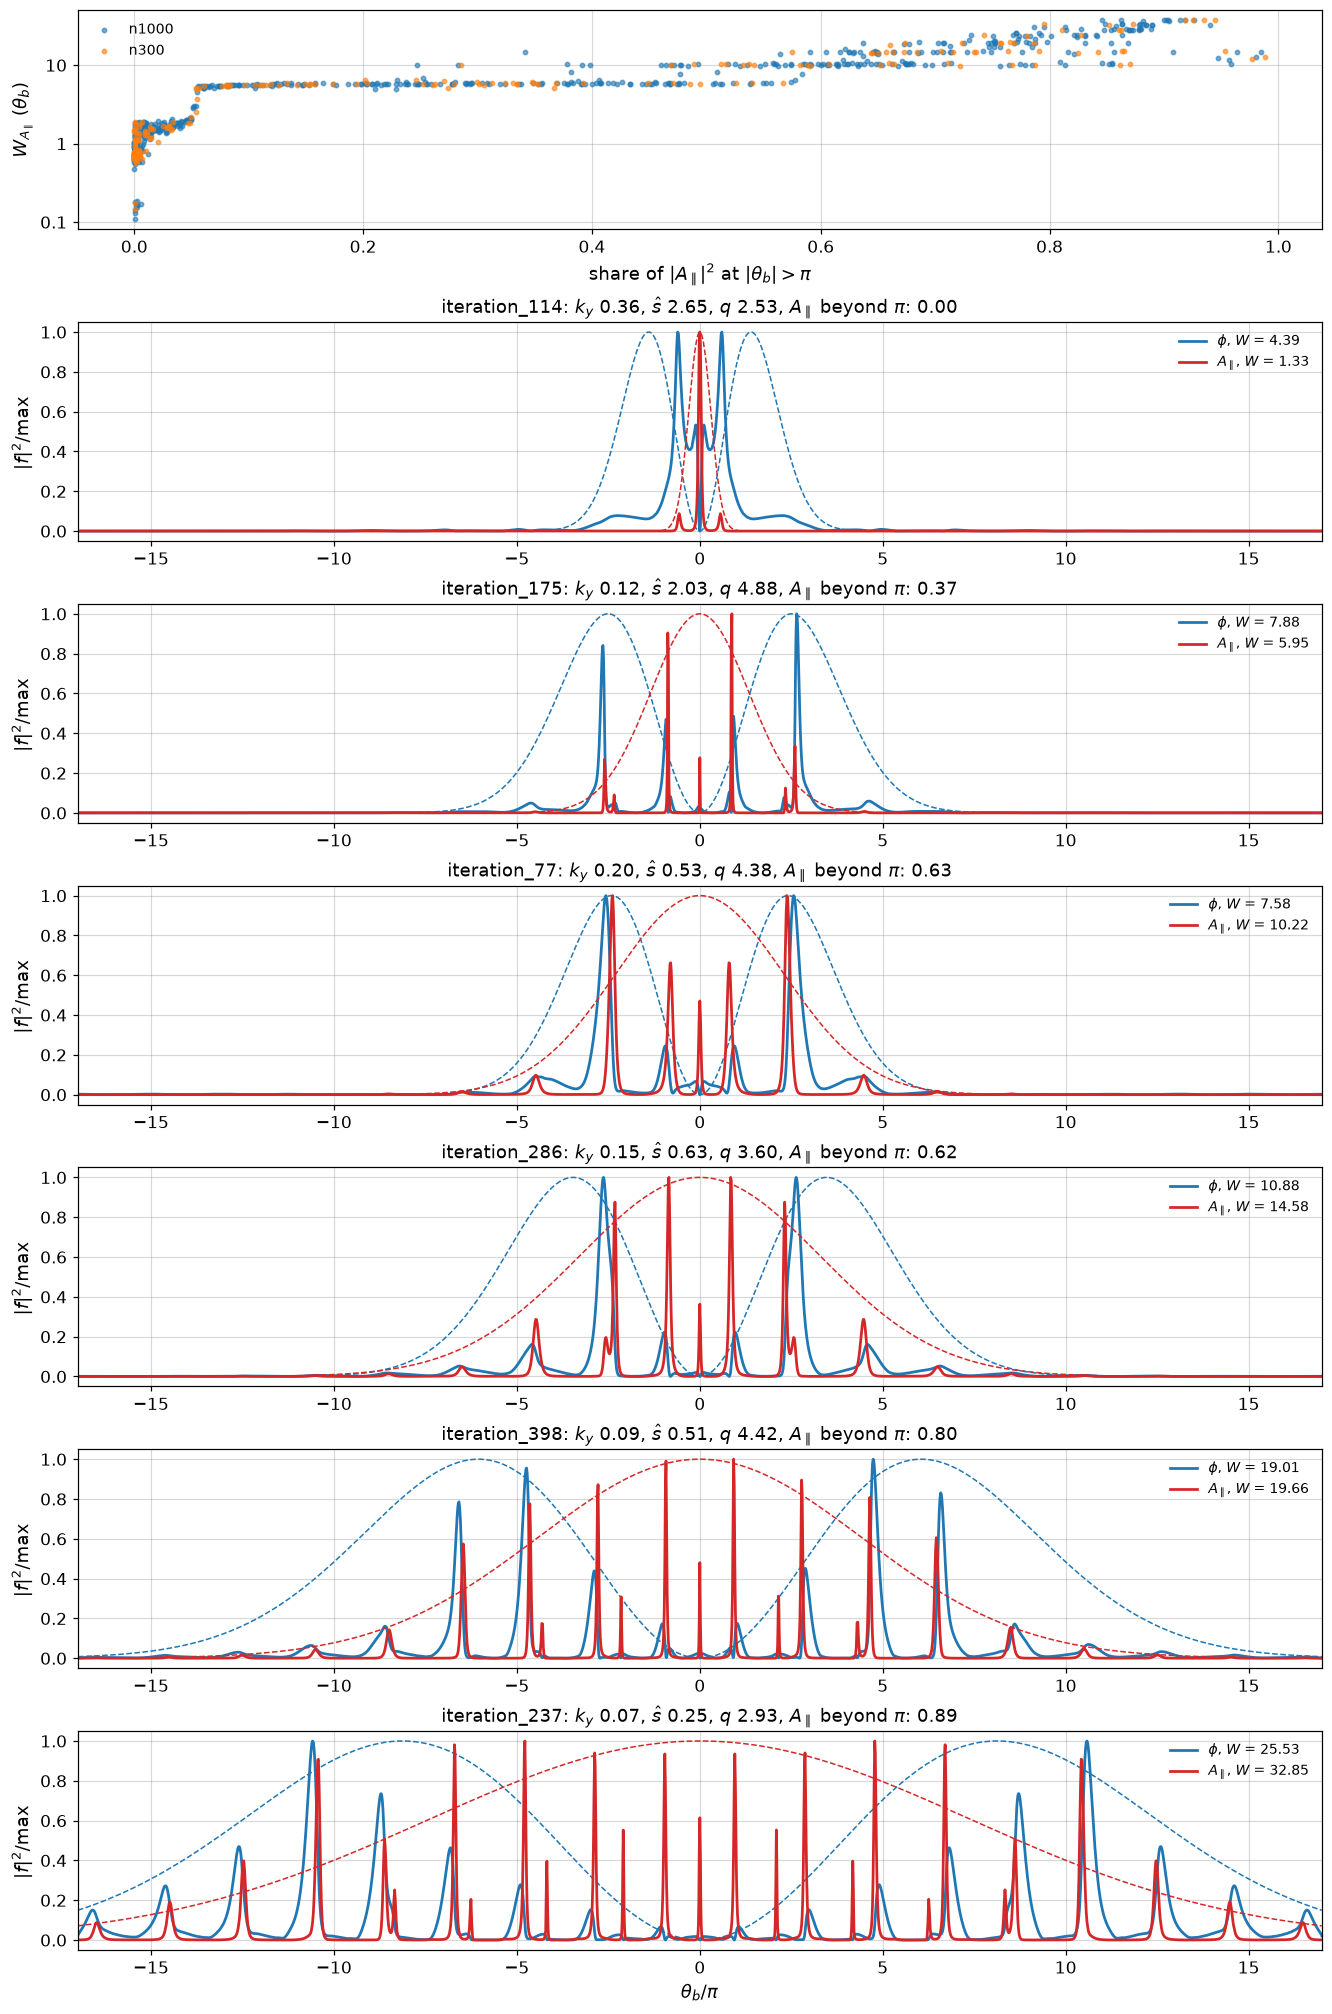

In [6]:
band_edges = [0, 3, 8, 12.5, 17.5, 25, np.inf]
mtm["apar_band"] = pd.cut(mtm.apar_width, band_edges)
print(mtm.groupby("apar_band", observed=True).agg(n=("sample", "size"), apar_width_median=("apar_width", "median"),
                                                 apar_tail_median=("apar_tail_fraction", "median"), phi_width_median=("phi_width", "median"),
                                                 shat_median=("shat", "median"), q_median=("q", "median"), ky_median=("ky", "median")).round(3).to_string())
examples = [rows.iloc[(rows.gamma - rows.gamma.median()).abs().argmin()] for _, rows in mtm[mtm.draw == "n1000"].groupby("apar_band", observed=True)
            if len(rows) >= 5]
fig, axes = plt.subplots(1 + len(examples), 1, figsize=(12, 2.6 * (1 + len(examples))), constrained_layout=True)
for draw, colour in zip(draws, ("C0", "C1")):
    rows = mtm[mtm.draw == draw]
    axes[0].scatter(rows.apar_tail_fraction, rows.apar_width, s=8, color=colour, alpha=0.6, label=draw)
axes[0].set(yscale="log", xlabel=r"share of $|A_\parallel|^2$ at $|\theta_b|>\pi$", ylabel=r"$W_{A_\parallel}$ ($\theta_b$)")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:g}")); axes[0].yaxis.set_minor_locator(NullLocator()); axes[0].legend(fontsize=9)
for ax, example in zip(axes[1:], examples):
    scan = gs2_scans["n1000"]
    output = scan.gk_output.data.set_index(sample="sample_name").sel(sample=example["sample"])
    finite_theta = output.apar.pint.dequantify().dropna("theta").sortby("theta").theta
    basis_angle = FieldLine(scan.sample_pyro(example["sample"], gk_output=xr.Dataset())).compute_basis_angle(finite_theta.values)
    for field, colour in zip(fields, ("C0", "C3")):
        power = np.abs(output[field].pint.dequantify().sel(theta=finite_theta).values) ** 2
        ax.plot(basis_angle / np.pi, power / power.max(), color=colour, marker="", label=f"{field_label[field]}, $W$ = {example[f'{field}_width']:.2f}")
        width = example[f"{field}_width"]
        ax.plot(basis_angle / np.pi, np.abs(model[mtm_parity[field]](basis_angle / width)) ** 2 / np.abs(model[mtm_parity[field]](basis_angle / width)).max() ** 2,
                color=colour, ls="--", lw=1, marker="")
    ax.set(xlim=(-17, 17), ylabel=r"$|f|^2/\max$", title=f"{example['sample']}: $k_y$ {example.ky:.2f}, $\\hat s$ {example.shat:.2f}, $q$ {example.q:.2f}, "
           f"$A_\\parallel$ beyond $\\pi$: {example.apar_tail_fraction:.2f}")
    ax.legend(fontsize=9, loc="upper right")
axes[-1].set_xlabel(r"$\theta_b/\pi$")

plt.show()

## Distributions of $W_\phi$, $W_{A_\parallel}$ and $s^2=W_\phi/W_{A_\parallel}$
Kept modes in blue; censored modes (box contact, a lower bound on the width) stacked in red. Medians are Kaplan–Meier medians
where censoring matters (below).

     draw quantity    n  censored  km_q10  km_q25  km_q50  km_q75  km_q90
0   n1000      phi  683        58   4.208   5.643   7.882  12.655  18.336
1   n1000     apar  683        35   0.712   1.318   5.605  10.252  19.409
2   n1000    ratio  683        58   0.872   1.063   2.024   4.630  11.745
3    n300      phi  202        14   4.351   5.968   8.052  12.487  16.272
4    n300     apar  202         9   0.732   1.274   5.629  10.241  17.992
5    n300    ratio  202        14   0.847   1.055   1.696   4.052  11.168
6  pooled      phi  885        72   4.209   5.711   7.959  12.545  17.606
7  pooled     apar  885        44   0.718   1.312   5.620  10.251  19.341
8  pooled    ratio  885        72   0.864   1.060   1.908   4.615  11.702


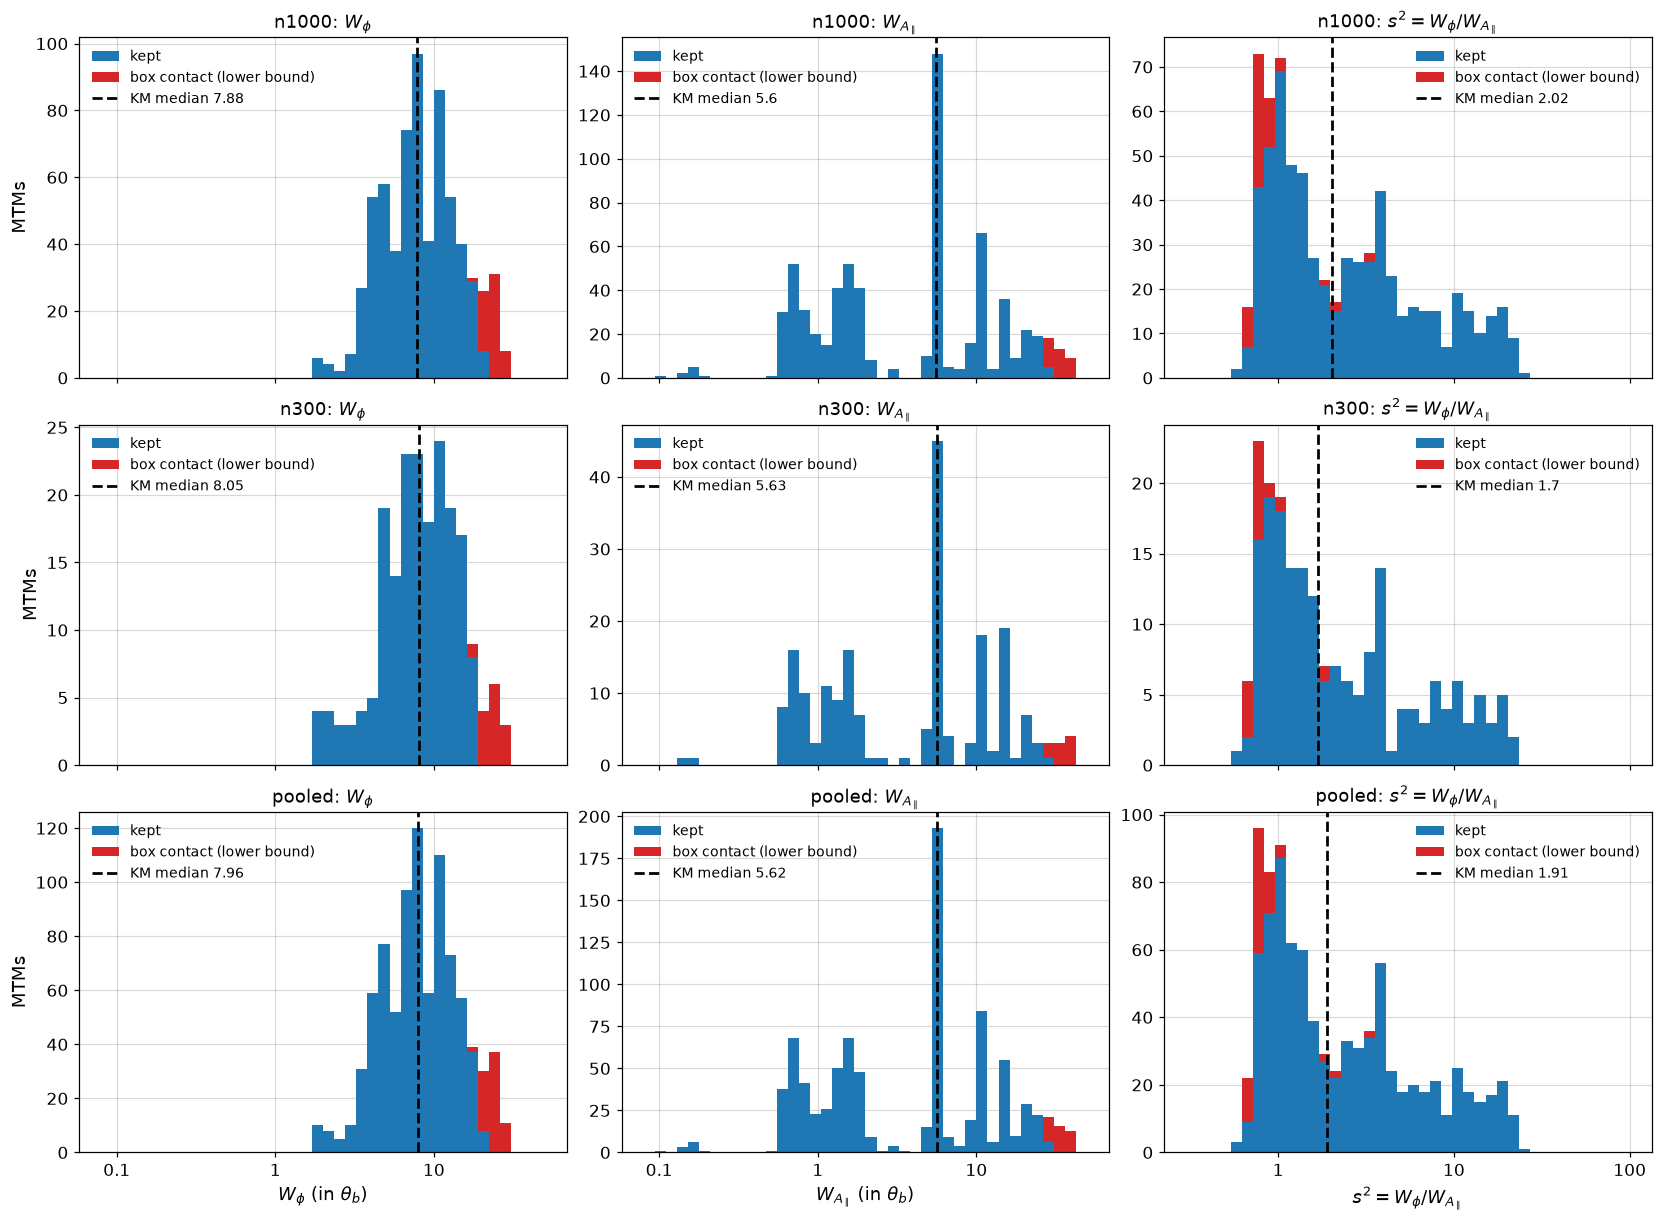

In [7]:
def km_quantile(values, censored, p):
    # p-quantile of right-censored values (Kaplan-Meier); NaN if the estimate never reaches p
    order = np.argsort(values)
    values, censored = np.asarray(values)[order], np.asarray(censored)[order]
    survival = np.cumprod(1 - (~censored) / (len(values) - np.arange(len(values))))
    hit = np.nonzero(1 - survival >= p)[0]
    return values[hit[0]] if len(hit) else np.nan


quantities = {"phi": ("phi_width", "phi_censored", rf"$W_\phi$"), "apar": ("apar_width", "apar_censored", r"$W_{A_\parallel}$"),
              "ratio": ("ratio", "ratio_censored", r"$s^2=W_\phi/W_{A_\parallel}$")}
summary_rows = []
for draw in (*draws, "pooled"):
    rows = mtm if draw == "pooled" else mtm[mtm.draw == draw]
    for quantity, (column, censored, _) in quantities.items():
        summary_rows.append(dict(draw=draw, quantity=quantity, n=len(rows), censored=int(rows[censored].sum()),
                                 **{f"km_q{int(100 * p)}": km_quantile(rows[column].values, rows[censored].values, p) for p in (0.1, 0.25, 0.5, 0.75, 0.9)}))
width_summary = pd.DataFrame(summary_rows)
width_summary.to_csv(plots_dir / "width_summary.csv", index=False)
print(width_summary.round(3).to_string())

bins = {"phi": np.geomspace(0.08, 50, 41), "apar": np.geomspace(0.08, 50, 41), "ratio": np.geomspace(0.3, 100, 41)}
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex="col", constrained_layout=True)
for row, draw in enumerate((*draws, "pooled")):
    rows = mtm if draw == "pooled" else mtm[mtm.draw == draw]
    for column, (quantity, (value, censored, label)) in enumerate(quantities.items()):
        ax = axes[row, column]
        clipped = rows[value].clip(bins[quantity][0] * 1.01, bins[quantity][-1] * 0.99)
        ax.hist([clipped[~rows[censored]], clipped[rows[censored]]], bins=bins[quantity], stacked=True, color=["C0", "C3"],
                label=["kept", "box contact (lower bound)"])
        median = width_summary.set_index(["draw", "quantity"]).loc[(draw, quantity), "km_q50"]
        ax.axvline(median, color="k", ls="--", label=f"KM median {median:.3g}")
        ax.set_xscale("log"); ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}")); ax.xaxis.set_minor_locator(NullLocator())
        ax.set_title(f"{draw}: {label}")
        ax.legend(fontsize=9)
        if row == 2:
            ax.set_xlabel(label + (r" (in $\theta_b$)" if quantity != "ratio" else ""))
    axes[row, 0].set_ylabel("MTMs")
fig.savefig(plots_dir / "gs2_mtm_width_histogram.png", dpi=150); fig.savefig(plots_dir / "gs2_mtm_width_histogram.pdf")
plt.show()

Low-level view: each MTM's $W_{A_\parallel}$ against $W_\phi$, coloured by $\hat s$; dotted lines of constant $s^2$.

## Width laws
Per field, $\ln W_f=c+a\ln k_y+b\ln\hat s+d\ln q$ on n1000, Tobit with the box-contact modes right-censored, 400-sample bootstrap 95 %
intervals; the margin is the Kaplan–Meier 95th percentile of $\ln(W/{\rm centre})$; coverage out of sample on n300. The fit and margin
code is the law2 refit's (`mtm_extent_law_refit_nstx.ipynb`). $k_y$, $\hat s$, $q$ are the cube coordinates.

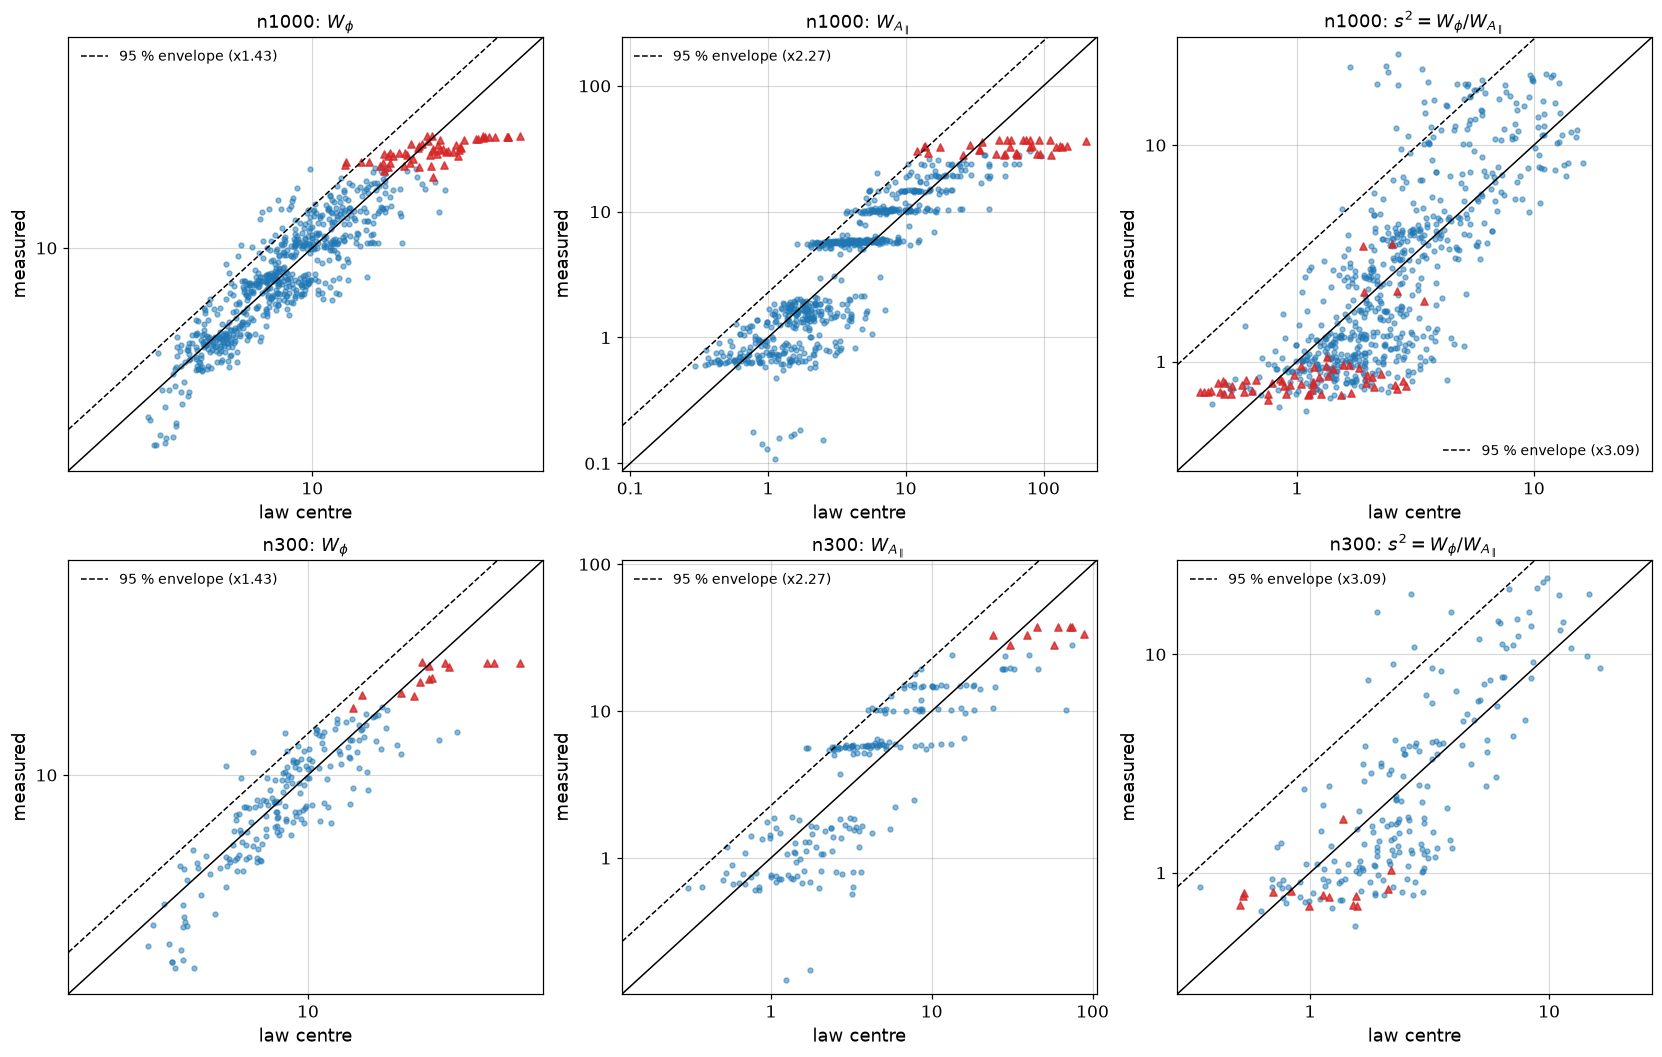

In [9]:
law_names = ["ky", "shat", "q"]

def design(rows):
    return np.column_stack([np.ones(len(rows))] + [np.log(rows[name].values) for name in law_names])

def tobit_fit(X, y, censored, start):
    def negative_log_likelihood(parameters):
        z = (y - X @ parameters[:-1]) / np.exp(parameters[-1])
        return -(stats.norm.logpdf(z[~censored]) - parameters[-1]).sum() - stats.norm.logsf(z[censored]).sum()
    return optimize.minimize(negative_log_likelihood, start, method="BFGS").x

def tobit(rows, value, censored, n_boot=400, seed=0):
    X, y, censored = design(rows), np.log(rows[value].values), rows[censored].values
    ols = np.linalg.lstsq(X[~censored], y[~censored], rcond=None)[0]
    start = np.r_[ols, np.log(np.std(y[~censored] - X[~censored] @ ols))]
    best = tobit_fit(X, y, censored, start)
    rng = np.random.default_rng(seed)
    boot = np.array([tobit_fit(X[pick], y[pick], censored[pick], best) for pick in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))])
    low, high = np.percentile(boot, [2.5, 97.5], axis=0)
    return dict(coefficients=best[:-1], low=low[:-1], high=high[:-1], sigma=float(np.exp(best[-1])), n=len(y), n_censored=int(censored.sum()))

def coverage(rows, value, censored, envelope):
    ratio = rows[value] / envelope
    return dict(below=float(((ratio <= 1) & ~rows[censored]).mean()), above_sure=float((ratio > 1).mean()),
                undetermined=float(((ratio <= 1) & rows[censored]).mean()), median_ratio=float(ratio[~rows[censored]].median()))

fit_rows = mtm[mtm.draw == "n1000"]
laws, law_rows = {}, []
for quantity in ("phi", "apar", "ratio"):
    value, censored, _ = quantities[quantity]
    law = tobit(fit_rows, value, censored)
    centre = lambda rows, law=law: np.exp(design(rows) @ law["coefficients"])
    margin = float(np.exp(km_quantile(np.log(fit_rows[value].values / centre(fit_rows)), fit_rows[censored].values, 0.95)))
    laws[quantity] = dict(**law, margin=margin, centre=centre)
    out_of_sample = mtm[mtm.draw == "n300"]
    law_rows.append(dict(quantity=quantity, prefactor_centre=np.exp(law["coefficients"][0]), margin_km95=margin,
                         **{f"{name}_exponent": law["coefficients"][j + 1] for j, name in enumerate(law_names)},
                         **{f"{name}_ci_half": (law["high"][j + 1] - law["low"][j + 1]) / 2 for j, name in enumerate(law_names)},
                         sigma=law["sigma"], n=law["n"], n_censored=law["n_censored"],
                         **{f"n1000_{key}": val for key, val in coverage(fit_rows, value, censored, centre(fit_rows) * margin).items()},
                         **{f"n300_{key}": val for key, val in coverage(out_of_sample, value, censored, centre(out_of_sample) * margin).items()}))
law_table = pd.DataFrame(law_rows)
law_table.to_csv(plots_dir / "width_laws.csv", index=False)
print(law_table.round(3).T.to_string())
for quantity, law in laws.items():
    print(f"{quantity}: W = {np.exp(law['coefficients'][0]):.4f} ky^{law['coefficients'][1]:+.3f} shat^{law['coefficients'][2]:+.3f} "
          f"q^{law['coefficients'][3]:+.3f}  (centre; x {law['margin']:.3f} for the 95 % envelope), sigma {law['sigma']:.3f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), constrained_layout=True)
for row, draw in enumerate(draws):
    rows = mtm[mtm.draw == draw]
    for column, quantity in enumerate(("phi", "apar", "ratio")):
        value, censored, label = quantities[quantity]
        ax = axes[row, column]
        predicted = laws[quantity]["centre"](rows)
        ax.scatter(predicted[~rows[censored]], rows[value][~rows[censored]], s=10, alpha=0.5, c="C0")
        ax.scatter(predicted[rows[censored]], rows[value][rows[censored]], s=22, marker="^", c="C3", alpha=0.8)
        limits = np.array([min(predicted.min(), rows[value].min()) * 0.8, max(predicted.max(), rows[value].max()) * 1.2])
        ax.plot(limits, limits, "k", lw=1, marker="")
        ax.plot(limits, limits * laws[quantity]["margin"], "k--", lw=1, marker="", label=f"95 % envelope (x{laws[quantity]['margin']:.2f})")
        ax.set(xscale="log", yscale="log", xlim=limits, ylim=limits, title=f"{draw}: {label}", xlabel=f"law centre", ylabel=f"measured")
        for axis in (ax.xaxis, ax.yaxis):
            axis.set_major_formatter(StrMethodFormatter("{x:.3g}")); axis.set_minor_locator(NullLocator())
        ax.legend(fontsize=9)

plt.show()

## Predicted settings
A Gaussian of width $sW$ expanded in $\psi_n(x)$, $r=(s^2-1)/(s^2+1)$ (qp5.49, Mehler): even
$\lvert c_{2k}\rvert^2/\lVert f\rVert^2=\sqrt{1-r^2}\binom{2k}{k}(r^2/4)^k$, odd $\lvert c_{2k+1}\rvert^2/\lVert f\rVert^2=(1-r^2)^{3/2}(2k+1)\binom{2k}{k}(r^2/4)^k$.
$N_f(s,\epsilon)$ is the exact count at relative $L^2$ error $\epsilon=3\,\%$, with the odd form for $\phi$ and the even form for
$A_\parallel$ (MTM parity); the even count is bounded by $N\le2\ln(1/\epsilon)/\ln\lvert(s^2+1)/(s^2-1)\rvert$.

**The rule** (closed form from the laws, O(1) per case): WIDTH $=\sqrt{\hat W_\phi\hat W_{A_\parallel}}$ (law centres), NBASIS $=\max_f N_f$
at $s_f=W_f/{\rm WIDTH}$, NXGRID $=\max({\rm NBASIS}+6, 14)$, capped at 65 / 59. Evaluated with the law widths (what the rule sets) and
with each mode's measured widths (what it would need); the share above the cap is the share of MTMs that one WIDTH cannot cover.

draw                      n1000     n300
n                       683.000  202.000
width_median              5.258    5.273
nbasis_rule_median       10.000   10.000
rule_above_cap            0.010    0.015
measured_above_cap        0.110    0.129
oracle_above_cap          0.064    0.054
needed_measured_median   12.000   13.500
needed_oracle_median      6.000    6.000
phi_resolved              0.523    0.554
apar_resolved             0.649    0.579
both_resolved             0.363    0.322
seconds_per_case          0.000    0.000


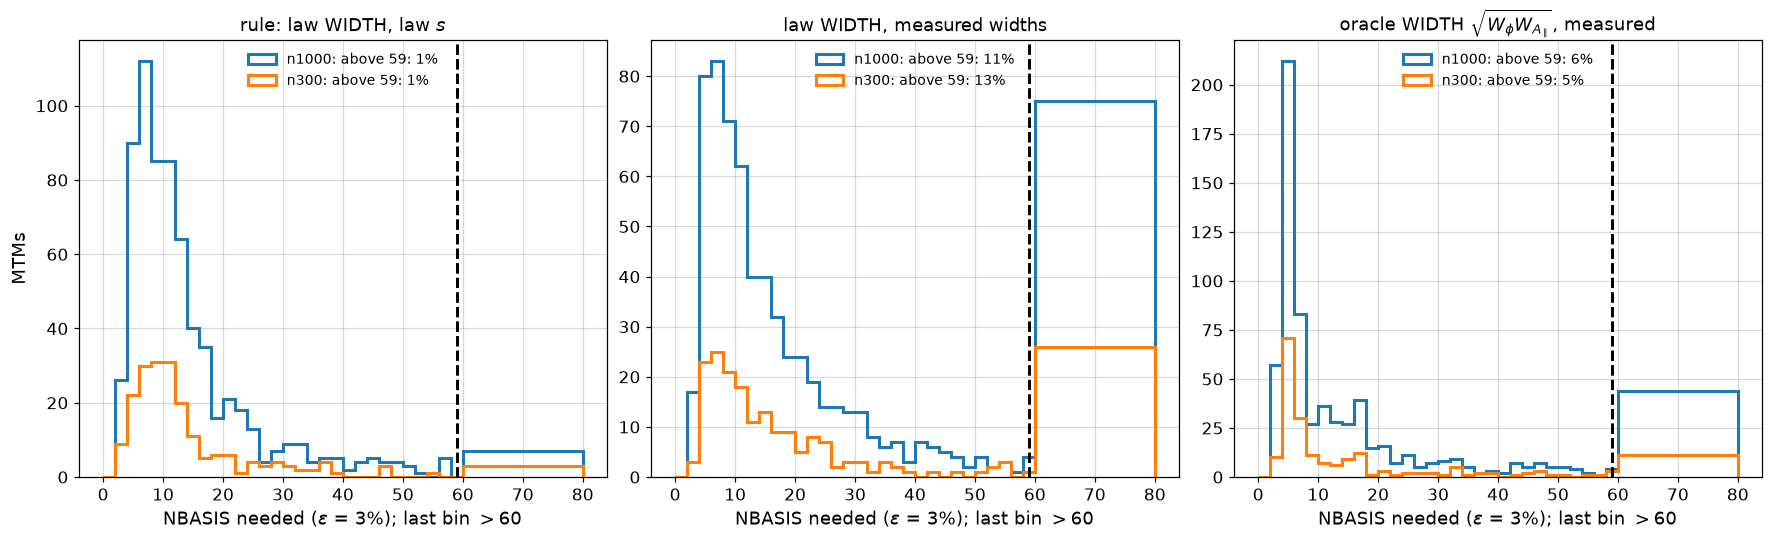

In [10]:
def model_fractions(s, parity, n_max=1200):
    r_squared = ((s ** 2 - 1) / (s ** 2 + 1)) ** 2
    k = np.arange(n_max // 2)
    central = np.cumprod(np.r_[1.0, (2 * k[1:] - 1) / (2 * k[1:])])        # binom(2k, k) / 4^k
    fractions = np.zeros(n_max)
    if parity == "even":
        fractions[0::2] = np.sqrt(1 - r_squared) * central * r_squared ** k
    else:
        fractions[1::2] = (1 - r_squared) ** 1.5 * (2 * k + 1) * central * r_squared ** k
    return fractions


def model_nbasis(s, parity, tolerance=target_error):
    error = np.sqrt(np.maximum(1 - np.cumsum(model_fractions(s, parity)), 0))
    return int(np.argmax(error <= tolerance)) + 1 if (error <= tolerance).any() else np.inf


def model_error(s, parity, nbasis):
    return float(np.sqrt(max(1 - model_fractions(s, parity)[:int(nbasis)].sum(), 0)))


for s in (0.3, 0.7, 3.0):
    assert model_nbasis(s, "even", 0.01) <= 2 * np.log(100) / np.log(abs((s ** 2 + 1) / (s ** 2 - 1))) + 1


def rule(rows):
    # closed form from the two width laws: WIDTH, NBASIS, NXGRID per case
    width_phi, width_apar = laws["phi"]["centre"](rows), laws["apar"]["centre"](rows)
    width = np.sqrt(width_phi * width_apar)
    needed = np.array([max(model_nbasis(s, mtm_parity["phi"]), model_nbasis(1 / s, mtm_parity["apar"])) for s in np.sqrt(width_phi / width_apar)])
    nbasis = np.minimum(needed, nbasis_cap)
    return pd.DataFrame(dict(width=width, nbasis_needed=needed, nbasis=nbasis, nxgrid=np.clip(nbasis + 6, nxgrid_floor, nxgrid_cap)), index=rows.index)


start = time.perf_counter()
settings = rule(mtm)
seconds_per_case = (time.perf_counter() - start) / len(mtm)
for field in fields:
    settings[f"s_{field}"] = mtm[f"{field}_width"] / settings.width
    settings[f"{field}_needed"] = [model_nbasis(s, mtm_parity[field]) for s in settings[f"s_{field}"]]
    settings[f"{field}_error"] = [model_error(s, mtm_parity[field], nbasis) for s, nbasis in zip(settings[f"s_{field}"], settings.nbasis)]
settings["needed_measured"] = settings[["phi_needed", "apar_needed"]].max(axis=1)
oracle_width = np.sqrt(mtm.phi_width * mtm.apar_width)
settings["needed_oracle"] = [max(model_nbasis(s, mtm_parity["phi"]), model_nbasis(1 / s, mtm_parity["apar"])) for s in np.sqrt(mtm.ratio)]
settings = settings.join(mtm[["draw", "phi_censored", "apar_censored"]])
settings_summary = settings.groupby("draw").agg(
    n=("width", "size"), width_median=("width", "median"), nbasis_rule_median=("gs2_mtm_nbasis_needed_histogram", "median"),
    rule_above_cap=("gs2_mtm_nbasis_needed_histogram", lambda n: (n > nbasis_cap).mean()),
    measured_above_cap=("needed_measured", lambda n: (n > nbasis_cap).mean()), oracle_above_cap=("needed_oracle", lambda n: (n > nbasis_cap).mean()),
    needed_measured_median=("needed_measured", "median"), needed_oracle_median=("needed_oracle", "median"),
    phi_resolved=("phi_error", lambda e: (e <= target_error).mean()), apar_resolved=("apar_error", lambda e: (e <= target_error).mean()),
    both_resolved=("phi_error", lambda e: ((e <= target_error) & (settings.loc[e.index, "apar_error"] <= target_error)).mean()))
settings_summary["seconds_per_case"] = seconds_per_case
settings_summary.to_csv(plots_dir / "predicted_settings_summary.csv")
print(settings_summary.round(3).T.to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
nbasis_bins = np.r_[np.arange(0, 62, 2), 80]
for draw, colour in zip(draws, ("C0", "C1")):
    rows = settings[settings.draw == draw]
    for ax, column, title in zip(axes, ("gs2_mtm_nbasis_needed_histogram", "needed_measured", "needed_oracle"),
                                 ("rule: law WIDTH, law $s$", "law WIDTH, measured widths", r"oracle WIDTH $\sqrt{W_\phi W_{A_\parallel}}$, measured")):
        ax.hist(np.clip(rows[column], 0, 79), bins=nbasis_bins, histtype="step", lw=2, color=colour,
                label=f"{draw}: above {nbasis_cap}: {(rows[column] > nbasis_cap).mean():.0%}")
        ax.axvline(nbasis_cap, color="k", ls="--")
        ax.set(xlabel=rf"NBASIS needed ($\epsilon$ = {target_error:.0%}); last bin $>$60", title=title)
        ax.legend(fontsize=9)
axes[0].set_ylabel("MTMs")
fig.savefig(plots_dir / "gs2_mtm_nbasis_needed_histogram.png", dpi=150); fig.savefig(plots_dir / "gs2_mtm_nbasis_needed_histogram.pdf")
plt.show()